# 02 — Nettoyage (Pump Sensor Data)

Objectifs :
1. Retirer les capteurs morts.
2. Masquer les séquences figées (≥ 24 h) : ce ne sont pas de vraies mesures.
3. Remplir les trous courts (≤ 5 min) avec la dernière valeur connue.
4. Lister les capteurs utilisables par les modèles multivariés.
5. Sauvegarder le jeu nettoyé dans `data/processed/`.

Règles du protocole respectées :
- aucune ligne supprimée, aucune valeur extrême supprimée (ce sont des anomalies potentielles) ;
- aucune statistique apprise sur les données : l'imputation apprise se fera dans chaque pli (phase 4) ;
- remplissage causal : jamais de valeur future, jamais à travers un changement de statut.

Toute la logique est dans `src/cleaning.py`. Ce notebook ne fait qu'orchestrer et afficher.

Prérequis : `data/raw/sensor.csv` et le notebook 01 exécuté une fois.

In [8]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.cleaning import clean_pump
from src.config import TABLES
from src.data_loading import STATUS_COL, load_pump, pump_sensor_columns
from src.quality import classify_sensors, profile_sensors

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 200)

## 1. Chargement et capteurs morts

In [9]:
df = load_pump()
sensors = pump_sensor_columns(df)
print(f"{df.shape[0]:,} lignes × {len(sensors)} capteurs")

classified = classify_sensors(profile_sensors(df, sensors))
dead = classified.index[classified["status"] == "mort"].tolist()
print("Capteurs morts :", dead)

220,320 lignes × 52 capteurs
Capteurs morts : ['sensor_15']


## 2. Nettoyage

`clean_pump` enchaîne : retrait des capteurs morts → masquage des séquences figées → remplissage des trous courts.
Colonnes du rapport :
- `nan_brut_pct` : part de valeurs manquantes avant nettoyage ;
- `fige_masque_pct` : part de valeurs figées transformées en NaN ;
- `rempli_pct` : part de trous comblés par la dernière valeur connue ;
- `nan_final_pct` : part de NaN après nettoyage ;
- `statut` : `ok`, ou capteur exclu des variables s'il reste plus de 20 % de NaN.

In [10]:
result = clean_pump(df, sensors, dead_sensors=dead)

print("Capteurs retirés :", result.dropped)
print(f"Capteurs conservés dans les données : {result.data.shape[1] - 1}")
print(f"Capteurs utilisables comme variables : {len(result.features)}")
display(result.report[result.report["statut"] != "ok"])
display(result.report.sort_values("fige_masque_pct", ascending=False).head(12))

Capteurs retirés : {'sensor_15': 'mort (capteur inutilisable)'}
Capteurs conservés dans les données : 51
Capteurs utilisables comme variables : 50


,nan_brut_pct,fige_masque_pct,rempli_pct,nan_final_pct,statut
sensor_50,34.957,0.0,0.009,34.948,exclu des variables (NaN > 20%)


,nan_brut_pct,fige_masque_pct,rempli_pct,nan_final_pct,statut
sensor_19,0.007,5.420,0.006,5.422,ok
sensor_17,0.021,4.370,0.010,4.380,ok
sensor_18,0.021,4.370,0.010,4.380,ok
sensor_13,0.009,3.847,0.007,3.848,ok
sensor_05,0.009,3.760,0.007,3.761,ok
sensor_22,0.019,2.526,0.010,2.534,ok
sensor_51,6.982,1.046,0.012,8.016,ok
sensor_24,0.007,1.024,0.006,1.025,ok
sensor_12,0.009,0.923,0.007,0.925,ok
sensor_02,0.009,0.000,0.007,0.001,ok


## 3. Vérifications

Le nettoyage ne doit changer ni l'index ni les statuts, et ne doit supprimer aucune ligne.

In [11]:
assert result.data.index.equals(df.index), "l'index a changé"
assert (result.data[STATUS_COL] == df[STATUS_COL]).all(), "les statuts ont changé"
assert len(result.data) == len(df), "des lignes ont été supprimées"
print("Index, statuts et nombre de lignes inchangés ✔")

# Où les valeurs figées masquées se situent-elles ? (par statut de la machine)
by_status = result.frozen.groupby(df[STATUS_COL]).sum().sum(axis=1).to_frame("points_figes_masques")
display(by_status)

Index, statuts et nombre de lignes inchangés ✔


,points_figes_masques
machine_status,
NORMAL,39019
RECOVERING,21097
BROKEN,0


In [12]:
# Où sont les valeurs figées masquées, capteur par capteur ?
frozen_by_sensor = result.frozen.groupby(df[STATUS_COL]).sum().T
display(frozen_by_sensor[frozen_by_sensor.sum(axis=1) > 0].sort_values("NORMAL", ascending=False))

# Où sont les NaN qui restent ? (ils seront traités dans chaque pli en phase 4)
nan_by_status = result.data.drop(columns=STATUS_COL).isna().groupby(df[STATUS_COL]).sum().T
nan_by_status["total"] = nan_by_status.sum(axis=1)
display(nan_by_status[nan_by_status["total"] > 0].sort_values("NORMAL", ascending=False).head(15))

machine_status,NORMAL,RECOVERING,BROKEN
sensor_19,11942,0,0
sensor_17,9628,0,0
sensor_18,9628,0,0
sensor_22,5566,0,0
sensor_24,2255,0,0
sensor_05,0,8284,0
sensor_13,0,8475,0
sensor_12,0,2034,0
sensor_51,0,2304,0


machine_status,NORMAL,RECOVERING,BROKEN,total
sensor_50,76921,75,1,76997
sensor_51,12363,5297,1,17661
sensor_19,11945,0,0,11945
sensor_17,9651,0,0,9651
sensor_18,9651,0,0,9651
sensor_22,5584,0,0,5584
sensor_24,2258,0,0,2258
sensor_01,287,20,0,307
sensor_30,237,0,0,237
sensor_29,45,0,0,45


## 4. Avant / après sur un capteur figé

Moyenne horaire : la zone masquée apparaît comme un trou dans le graphique du bas.

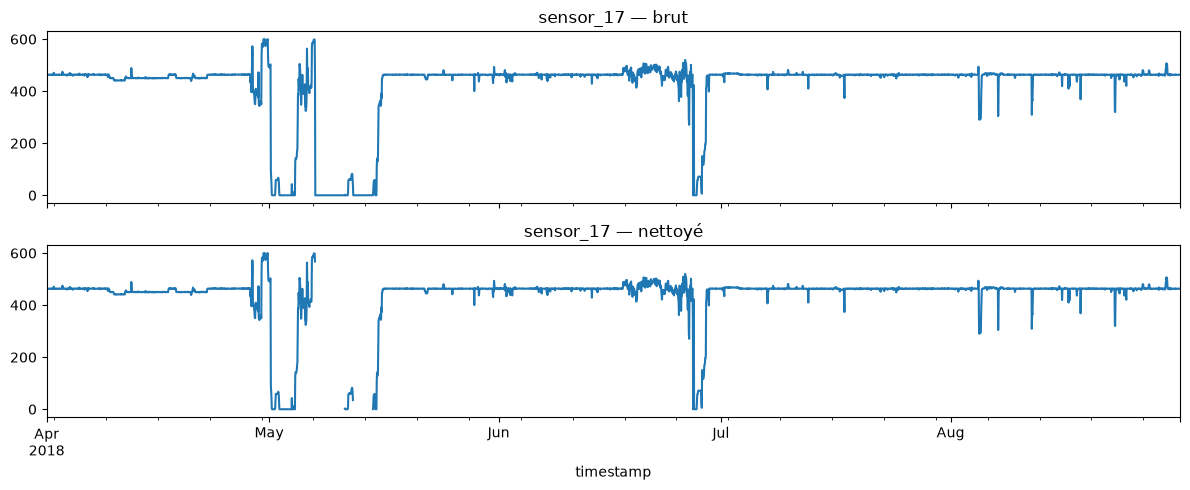

In [13]:
col = "sensor_17" if "sensor_17" in result.data.columns else result.report["fige_masque_pct"].idxmax()
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
df[col].resample("1h").mean().plot(ax=axes[0], title=f"{col} — brut")
result.data[col].resample("1h").mean().plot(ax=axes[1], title=f"{col} — nettoyé")
plt.tight_layout()
plt.show()

## 5. Sauvegarde

In [14]:
out = ROOT / "data" / "processed"
out.mkdir(parents=True, exist_ok=True)

result.data.to_csv(out / "pump_clean.csv.gz")
result.frozen.to_csv(out / "pump_frozen_flags.csv.gz")
result.report.to_csv(TABLES / "nettoyage_capteurs.csv")
pd.Series(result.features, name="capteur").to_csv(TABLES / "capteurs_variables.csv", index=False)

print("Fichiers écrits :")
print(" -", out / "pump_clean.csv.gz")
print(" -", out / "pump_frozen_flags.csv.gz")
print(" -", TABLES / "nettoyage_capteurs.csv")
print(" -", TABLES / "capteurs_variables.csv")

Fichiers écrits :
 - C:\Users\hp\Desktop\Projet-Capteurs\data\processed\pump_clean.csv.gz
 - C:\Users\hp\Desktop\Projet-Capteurs\data\processed\pump_frozen_flags.csv.gz
 - C:\Users\hp\Desktop\Projet-Capteurs\reports\tables\nettoyage_capteurs.csv
 - C:\Users\hp\Desktop\Projet-Capteurs\reports\tables\capteurs_variables.csv


## 6. Constats

- **Capteurs retirés** : `sensor_15` (100 % de NaN, inutilisable). 51 capteurs conservés dans le fichier nettoyé.
- **Capteurs exclus des variables** : `sensor_50` reste dans le fichier mais n'est pas utilisé comme variable. Il garde 34,9 % de NaN, et ses trous sont presque tous en zone NORMAL (76 921 sur 76 997), donc sans lien avec les arrêts. 50 capteurs sont utilisables.
- **Valeurs figées masquées (≥ 24 h)** : 9 capteurs, 60 116 points au total (39 019 en NORMAL, 21 097 en RECOVERING, 0 en BROKEN).
  - En NORMAL : `sensor_19` (11 942), `sensor_17` et `sensor_18` (9 628 chacun), `sensor_22` (5 566), `sensor_24` (2 255).
  - En RECOVERING : `sensor_13` (8 475), `sensor_05` (8 284), `sensor_51` (2 304), `sensor_12` (2 034).
  - `sensor_17` et `sensor_18` sont masqués exactement aux mêmes instants : cause commune probable (acquisition ou maintenance).
  - Sur `sensor_17`, la valeur reste à 0 plusieurs jours en mai alors que la machine est en statut NORMAL : panne du capteur ou arrêt non enregistré ? À valider avec Achraf.
- **Trous courts remplis (≤ 5 min)** : environ 0,01 % des points par capteur, soit quelques dizaines de points. Les autres trous sont longs et restent NaN.
- **NaN restants** : `sensor_50` 34,9 %, `sensor_51` 8,0 % (12 363 en NORMAL, 5 297 en RECOVERING), `sensor_19` 5,4 %, `sensor_00` 4,6 %, `sensor_17` et `sensor_18` 4,4 %, `sensor_13` et `sensor_05` 3,8 %, `sensor_22` 2,5 %, les autres moins de 1,1 %. Une grande partie est en zone NORMAL, donc dans la zone d'entraînement : ils devront être traités dans chaque pli en phase 4 (imputation apprise dans le pli, ou retrait de ces instants de l'entraînement), comme l'exige le protocole.
- **Décisions à valider avec Achraf** : (1) masquer les séquences figées de 24 h ou plus ; (2) remplir au plus 5 minutes par la dernière valeur connue ; (3) exclure `sensor_50` des variables.